# Thermal Neural Network (TNN) for the heat-pump BEV thermal model — PyTorch

Based on **Kirchgässner, Wallscheid & Böcker (2023), *Thermal neural networks: Lumped-parameter thermal modeling with state-space machine learning*, EAAI 117:105537**.

The TNN keeps the structure of a lumped-parameter thermal network and lets small neural networks supply the operating-point-dependent parameters, trained **end-to-end through the ODE rollout** (Eq. 8 in the paper):

$$\hat\vartheta_i[k+1] = \hat\vartheta_i[k] + T_s\,\kappa_i\Big(\pi_i[k] + \sum_{j\neq i}(\hat\vartheta_j-\hat\vartheta_i)\,\gamma_{ij}[k] + \sum_{j}(\tilde\vartheta_j-\hat\vartheta_i)\,\gamma_{ij}[k]\Big)$$

- $\gamma(\zeta)$: thermal conductances (an MLP) — the analogue of **our γ** (p1…p11 that scale terms of the COM)
- $\pi(\zeta)$: power losses (an MLP)
- $\kappa = 10^{\theta_c}$: inverse thermal capacitances (trainable constants)
- $\zeta = [\tilde\vartheta,\ \hat\vartheta,\ \xi]$: boundary temperatures, current state estimate, observables

**Notebook layout**
1. Load the HFM (Simscape) reference data from `../Data/tuning_data_*.mat`
2. **Part A – a TNN directly on our thermal nodes** (runs now): train on −5/−10 °C, test on the unseen −7 °C
3. Evaluate the way Prashant asked: **state-prediction error over a 30-s horizon** + free-run, compared with the nominal COM trajectory stored in the same files
4. **Part B – template for our actual method**: γ-net → *our* COM (`dynamics_mexfreeNew.m` ported to PyTorch) → loss on HFM states. Same training loop; only the dynamics function changes.

In [1]:
import os, time, math
from pathlib import Path
import numpy as np
import scipy.io as sio
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = torch.device("cpu")          # tiny recurrent model: CPU is as fast as GPU here
DTYPE  = torch.float32
DATA   = Path("..") / "Data"           # notebook lives in SSY226-Group2/python/
print("torch", torch.__version__, "| data dir exists:", DATA.exists())

torch 2.15.0+cpu | data dir exists: True


## 1. Data

Each `tuning_data_<T>.mat` is one 3600-s extended drive cycle at $T_{amb}=-T$ °C, sampled at 1 Hz.

- `resampled.*meas` = **HFM (Simscape) reference** → our ground truth
- `States` = the **COM simulated open loop** with the nominal parameters → the baseline to beat

Node choice for Part A (normalised as in the paper: temperatures in °C / 100):

| role | signals |
|---|---|
| thermal nodes $\hat\vartheta$ (m = 6) | motor, inverter, DC-DC, battery, cabin interior, cabin air |
| boundary nodes $\tilde\vartheta$ (n = 3) | ambient, inverter-coolant inlet, heater-coolant outlet, *+ vent air after inner condenser* |
| observables $\xi$ | compressor speed, blower flow, pump speed, coolant flows, battery current, heat loads (mot/inv/dcdc), heater cmd, refrigerant pressures |

Vehicle speed and battery/radiator-fan speeds are **not** in these files yet (see plan notes) — add them to `OBS` when the new export exists.

In [2]:
NODE_NAMES = ["motT", "invT", "dcdcT", "batT", "cabIntT", "cabAirT"]
BND_NAMES  = ["Tamb", "clntInvTin", "heaterClntTout", "ventAirT"]
OBS = {  # name: scale
    "compNrpm": 4500, "cabAirMfIn": 0.14, "motPumpNrpm": 900, "motClntMf": 0.33,
    "htxClntMf": 0.33, "batImeas": 175, "motQmeas": 4300, "invQmeas": 240,
    "dcdcQmeas": 240, "heaterCmd": 1.0, "compPinMpa": 0.3, "compPoutMpa": 4.0,
}

def K2C(x): return x - 273.15

def load_profile(T):
    d = sio.loadmat(DATA / f"tuning_data_{T}.mat", squeeze_me=True, struct_as_record=False)
    r, S = d["resampled"], d["States"]
    tamb = float(d["envTemp"])
    nodes = np.stack([r.motTmeasC, r.invTmeasC, r.dcdcTmeasC, r.batTmeasC,
                      K2C(r.cabIntTInK), r.cabAirTmeasC], 1)                    # °C, HFM
    bnd = np.stack([np.full_like(r.motTmeasC, tamb), r.clntInvTInC,
                    K2C(r.heaterClntToutMeasC), K2C(r.innerCondAirToutK)], 1)    # °C
    obs = np.stack([np.asarray(getattr(r, k), float) / s for k, s in OBS.items()], 1)
    com = np.stack([K2C(S[0]), K2C(S[1]), K2C(S[2]), K2C(S[4]), K2C(S[7]), K2C(S[8])], 1)  # nominal COM
    return dict(T=tamb, nodes=nodes, bnd=bnd, obs=np.nan_to_num(obs), com=com)

profiles = {T: load_profile(T) for T in (5, 7, 10)}
for T, p in profiles.items():
    print(f"Tamb={p['T']:+.0f} °C  N={len(p['nodes'])}  nodes range {p['nodes'].min():.1f}..{p['nodes'].max():.1f} °C")

Tamb=-5 °C  N=3601  nodes range -5.0..37.4 °C
Tamb=-7 °C  N=3601  nodes range -7.0..36.2 °C
Tamb=-10 °C  N=3601  nodes range -10.0..34.9 °C


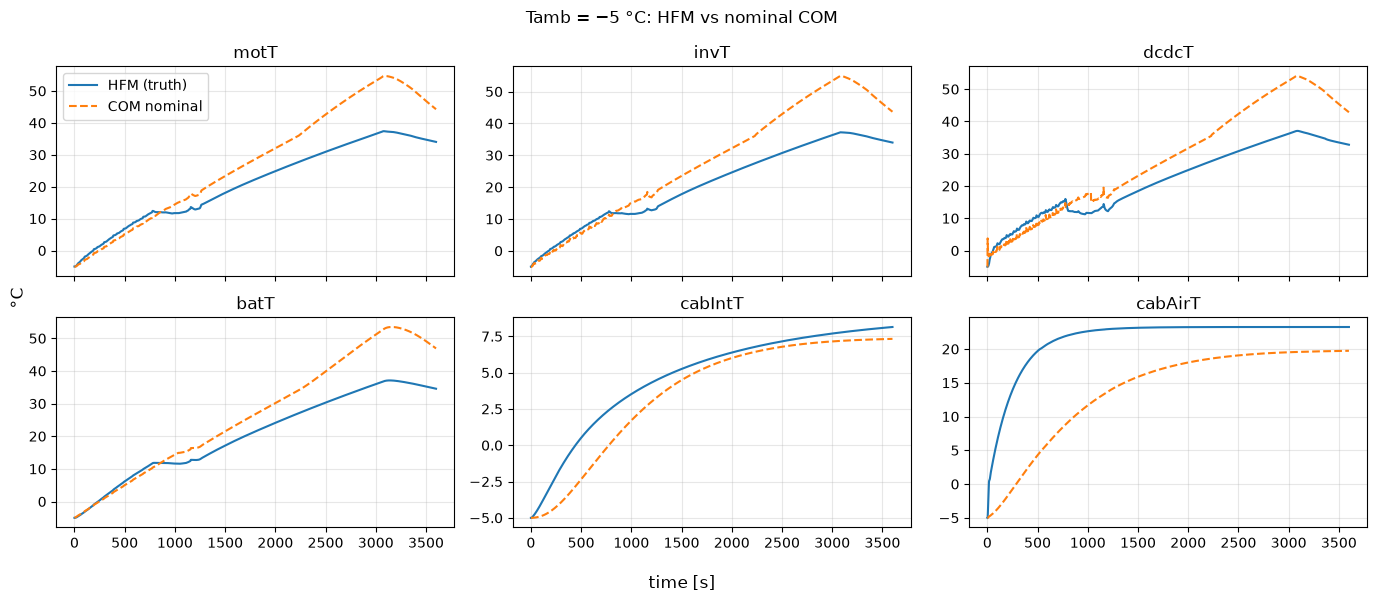

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
p = profiles[5]; t = np.arange(len(p["nodes"]))
for i, a in enumerate(ax.flat):
    a.plot(t, p["nodes"][:, i], label="HFM (truth)")
    a.plot(t, p["com"][:, i], "--", label="COM nominal")
    a.set_title(NODE_NAMES[i]); a.grid(alpha=.3)
ax[0, 0].legend(); fig.supxlabel("time [s]"); fig.supylabel("°C"); fig.suptitle("Tamb = −5 °C: HFM vs nominal COM")
plt.tight_layout()

In [4]:
SCALE_T = 100.0   # paper: temperatures / 100 °C
def to_tensors(p):
    x  = torch.tensor(p["nodes"] / SCALE_T, dtype=DTYPE)
    b  = torch.tensor(p["bnd"]   / SCALE_T, dtype=DTYPE)
    xi = torch.tensor(p["obs"],              dtype=DTYPE)
    return x, b, xi

TRAIN_T, TEST_T = (5, 10), (7,)          # unseen ambient temperature as test (project goal 4)
Xtr, Btr, Otr = map(lambda z: torch.stack(z), zip(*[to_tensors(profiles[T]) for T in TRAIN_T]))  # [P, N, .]
Xte, Bte, Ote = map(lambda z: torch.stack(z), zip(*[to_tensors(profiles[T]) for T in TEST_T]))
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

train (2, 3601, 6) test (1, 3601, 6)


## 2. Part A — the TNN cell (paper Eq. 8–9)

- `gamma_net`: $\zeta \to$ one conductance per node pair, made non-negative (paper recommends this; here `softplus`)
- `pi_net`: $\zeta \to$ power loss per thermal node
- `kappa = 10**theta_c`: one inverse capacitance per thermal node
- Explicit Euler with $T_s = 1$ s, exactly like Eq. 8

In [5]:
def mlp(n_in, n_out, hidden=(32, 32), act=nn.Tanh, out_act=None):
    layers, d = [], n_in
    for h in hidden:
        layers += [nn.Linear(d, h), act()]; d = h
    layers += [nn.Linear(d, n_out)]
    if out_act is not None: layers += [out_act()]
    return nn.Sequential(*layers)

class TNNCell(nn.Module):
    def __init__(self, m, n, n_obs, Ts=1.0, hidden=(32, 32)):
        super().__init__()
        self.m, self.n, self.Ts = m, n, Ts
        N = m + n
        iu = torch.triu_indices(N, N, offset=1)
        self.register_buffer("iu", iu)                    # node pairs (i<j)
        n_pairs = iu.shape[1]
        n_in = m + n + n_obs                              # zeta = [theta_hat, theta_tilde, xi]
        self.gamma_net = mlp(n_in, n_pairs, hidden, out_act=nn.Softplus)
        self.pi_net    = mlp(n_in, m, hidden)             # may be +/- (cooling via pi is allowed)
        self.theta_c   = nn.Parameter(torch.full((m,), -1.0))   # kappa = 10**theta_c

    def conductance_matrix(self, g):
        B, N = g.shape[0], self.m + self.n
        G = g.new_zeros(B, N, N)
        G[:, self.iu[0], self.iu[1]] = g
        return G + G.transpose(1, 2)                      # symmetric, zero diagonal

    def forward(self, x, bnd, xi):
        zeta = torch.cat([x, bnd, xi], -1)
        g    = self.gamma_net(zeta)                       # [B, pairs]
        G    = self.conductance_matrix(g)                 # [B, N, N]
        all_T = torch.cat([x, bnd], -1)                   # [B, N]
        dT    = all_T.unsqueeze(1) - x.unsqueeze(2)       # [B, m, N]: theta_j - theta_i
        heat  = (G[:, :self.m, :] * dT).sum(-1)           # sum_j (theta_j - theta_i) gamma_ij
        kappa = 10.0 ** self.theta_c
        return x + self.Ts * kappa * (self.pi_net(zeta) + heat), g

class TNN(nn.Module):
    def __init__(self, *a, **k):
        super().__init__(); self.cell = TNNCell(*a, **k)
    def forward(self, x0, bnd, xi):
        # bnd, xi: [B, L, .]; returns predicted states for steps 1..L  ([B, L, m])
        x, out = x0, []
        for k in range(bnd.shape[1]):
            x, _ = self.cell(x, bnd[:, k], xi[:, k])
            out.append(x)
        return torch.stack(out, 1)

model = TNN(m=len(NODE_NAMES), n=len(BND_NAMES), n_obs=len(OBS)).to(DEVICE)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

trainable parameters: 5,273


## 3. Training — truncated back-propagation through time (TBPTT)

As in the paper: whole profiles in parallel, gradients truncated every `TBPTT` steps (state carried over, graph detached), Nadam optimiser, gradient clipping against exploding gradients.

epoch   0  train RMSE   7.37 °C   lr 3.0e-03       2s


epoch   5  train RMSE   2.10 °C   lr 3.0e-03      13s


epoch  10  train RMSE   1.60 °C   lr 3.0e-03      23s


epoch  15  train RMSE   1.13 °C   lr 3.0e-03      33s


epoch  20  train RMSE   0.84 °C   lr 3.0e-03      44s


epoch  25  train RMSE   0.66 °C   lr 3.0e-03      54s


... (3 outputs left out)

epoch  45  train RMSE   0.34 °C   lr 3.0e-03      98s


epoch  50  train RMSE   0.32 °C   lr 3.0e-03     108s


epoch  55  train RMSE   0.31 °C   lr 3.0e-03     119s


epoch  59  train RMSE   0.32 °C   lr 3.0e-03     128s


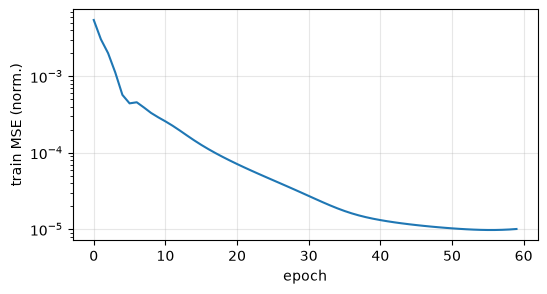

In [6]:
EPOCHS, TBPTT, LR = 60, 300, 3e-3
opt   = torch.optim.NAdam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)
lossf = nn.MSELoss()
hist = []
t0 = time.time()
for ep in range(EPOCHS):
    model.train(); x = Xtr[:, 0]; ep_loss = 0.0; n_chunks = 0
    for s in range(0, Xtr.shape[1] - 1, TBPTT):
        e = min(s + TBPTT, Xtr.shape[1] - 1)
        pred = model(x, Btr[:, s:e], Otr[:, s:e])          # predicts x[s+1 .. e]
        loss = lossf(pred, Xtr[:, s + 1:e + 1])
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        x = pred[:, -1].detach()                            # carry state, cut graph
        ep_loss += loss.item(); n_chunks += 1
    ep_loss /= n_chunks; hist.append(ep_loss); sched.step(ep_loss)
    if ep % 5 == 0 or ep == EPOCHS - 1:
        rmse_C = math.sqrt(ep_loss) * SCALE_T
        print(f"epoch {ep:3d}  train RMSE {rmse_C:6.2f} °C   lr {opt.param_groups[0]['lr']:.1e}   {time.time()-t0:5.0f}s")
plt.figure(figsize=(6, 3)); plt.semilogy(hist); plt.xlabel("epoch"); plt.ylabel("train MSE (norm.)"); plt.grid(alpha=.3)

## 4. Evaluation on the unseen ambient temperature (−7 °C)

**(a) 30-s horizon error** — the main measure agreed with the supervisor: start from the true state every 30 s, predict 30 steps ahead, average the error over all windows.
**(b) Free-run** over the full hour, compared with the COM trajectory stored in `States`.

> ⚠️ **Not a fair fight yet.** Part A's TNN is given the *measured* coolant / vent-air temperatures as boundary nodes, while the COM has to predict those itself from compressor, pumps and heat exchangers. Part A shows the TNN machinery works on our data; the meaningful comparison for the report is Part B (same COM, learned γ vs interpolated γ).

30-s horizon RMSE  motT      0.187 °C
30-s horizon RMSE  invT      0.150 °C
30-s horizon RMSE  dcdcT     0.236 °C
30-s horizon RMSE  batT      0.265 °C
30-s horizon RMSE  cabIntT   0.309 °C
30-s horizon RMSE  cabAirT   0.430 °C


Text(0.5, 1.0, 'TNN error growth over the 30-s MPC horizon (Tamb = −7 °C)')

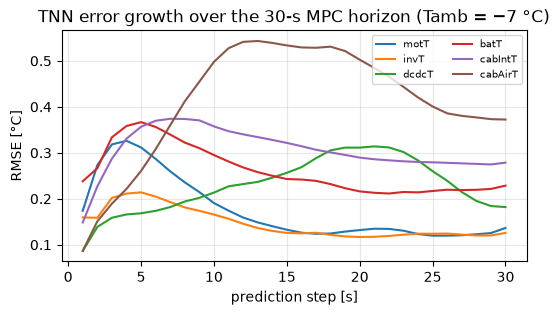

In [7]:
H = 30
@torch.no_grad()
def horizon_rmse(model, X, B, O, H=30):
    starts = torch.arange(0, X.shape[1] - H, H)
    x0 = X[0, starts]                                         # [W, m]
    idx = starts[:, None] + torch.arange(H)[None]             # [W, H]
    pred = model(x0, B[0, idx], O[0, idx])                    # [W, H, m]
    true = X[0, idx + 1]
    err = (pred - true) * SCALE_T
    return err.pow(2).mean((0, 1)).sqrt(), err.pow(2).mean(0).sqrt()   # per node, per horizon step

model.eval()
rmse_node, rmse_step = horizon_rmse(model, Xte, Bte, Ote, H)
for n, v in zip(NODE_NAMES, rmse_node): print(f"30-s horizon RMSE  {n:8s} {v:6.3f} °C")
plt.figure(figsize=(6, 3)); plt.plot(np.arange(1, H + 1), rmse_step.numpy())
plt.xlabel("prediction step [s]"); plt.ylabel("RMSE [°C]"); plt.legend(NODE_NAMES, fontsize=7, ncol=2); plt.grid(alpha=.3)
plt.title("TNN error growth over the 30-s MPC horizon (Tamb = −7 °C)")

node      COM nominal      TNN   (free-run RMSE, °C)
motT             8.71     0.19
invT             8.88     0.15
dcdcT            8.58     0.24
batT             8.04     0.27
cabIntT          1.29     0.32
cabAirT          8.75     0.46


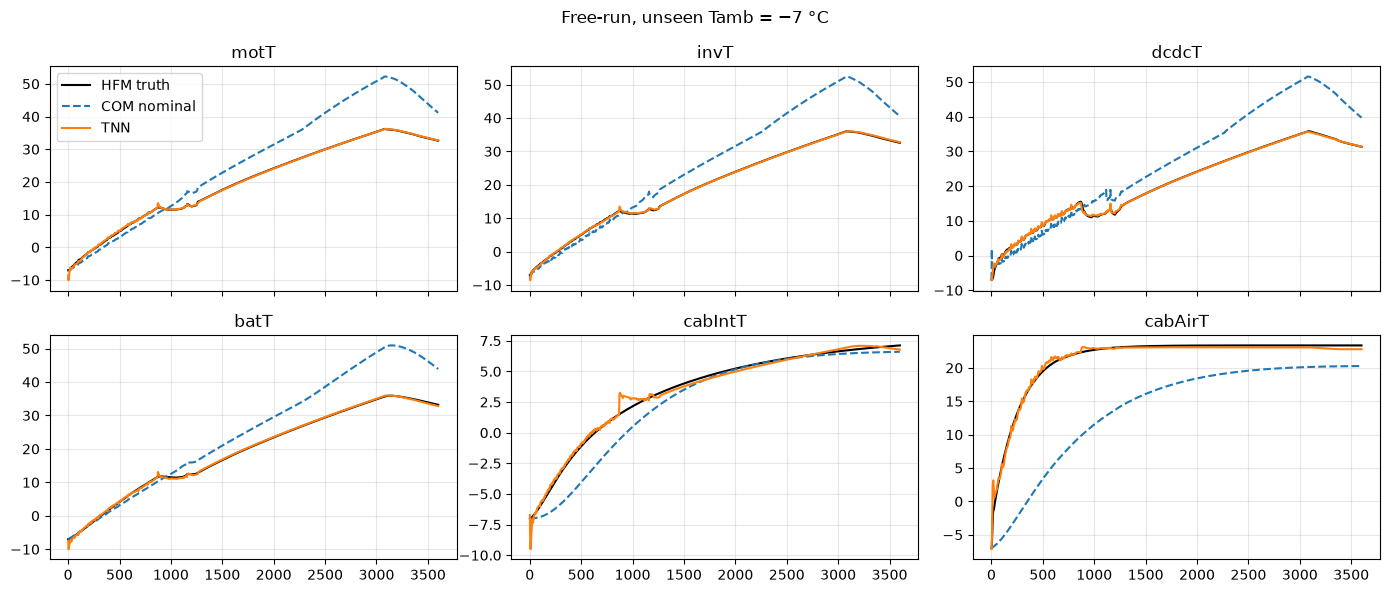

In [8]:
with torch.no_grad():
    free = model(Xte[:, 0], Bte[:, :-1], Ote[:, :-1])[0].numpy() * SCALE_T
truth = profiles[7]["nodes"][1:]; com = profiles[7]["com"][1:]
t = np.arange(1, len(truth) + 1)
fig, ax = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for i, a in enumerate(ax.flat):
    a.plot(t, truth[:, i], "k", lw=1.5, label="HFM truth")
    a.plot(t, com[:, i], "--", label="COM nominal")
    a.plot(t, free[:, i], label="TNN")
    a.set_title(NODE_NAMES[i]); a.grid(alpha=.3)
ax[0, 0].legend(); fig.suptitle("Free-run, unseen Tamb = −7 °C"); plt.tight_layout()

def rmse(a, b): return np.sqrt(((a - b) ** 2).mean(0))
print(f"{'node':8s} {'COM nominal':>12s} {'TNN':>8s}   (free-run RMSE, °C)")
for n, c, m_ in zip(NODE_NAMES, rmse(com, truth), rmse(free, truth)):
    print(f"{n:8s} {c:12.2f} {m_:8.2f}")

saved tnn_partA.pt


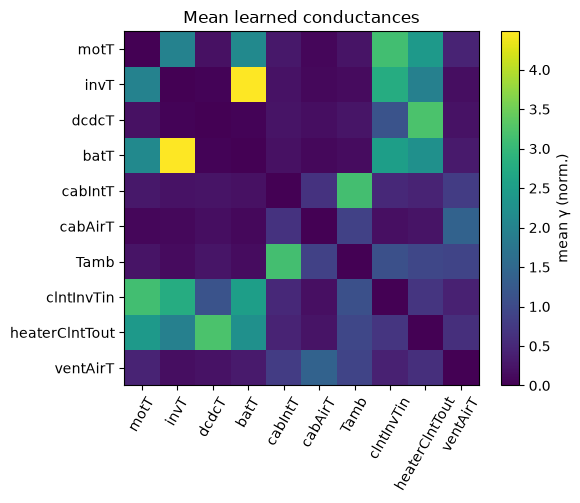

In [9]:
# Learned conductances over the test cycle -> which node pairs matter (paper Sec. 3.3: prune weak links)
with torch.no_grad():
    x, gs = Xte[:, 0], []
    for k in range(Xte.shape[1] - 1):
        x, g = model.cell(x, Bte[:, k], Ote[:, k]); gs.append(g)
    g_mean = torch.cat(gs).mean(0)
ALL = NODE_NAMES + BND_NAMES
Gm = model.cell.conductance_matrix(g_mean[None])[0].numpy()
plt.figure(figsize=(6, 5)); plt.imshow(Gm, cmap="viridis"); plt.colorbar(label="mean γ (norm.)")
plt.xticks(range(len(ALL)), ALL, rotation=60); plt.yticks(range(len(ALL)), ALL); plt.title("Mean learned conductances")
plt.tight_layout()
torch.save(model.state_dict(), "tnn_partA.pt"); print("saved tnn_partA.pt")

## 5. Part B — template for *our* method: γ-net → COM → HFM-state loss

Our setting is the same idea with a richer physics model: the COM (`Source Files/dynamics_mexfreeNew.m`) is fixed, and a network replaces the interpolation table in `prepParaVec.m` by predicting the 11 multipliers

| γ | scales (in `dynamics_mexfreeNew.m`) |
|---|---|
| p1, p2, p8 | cabin interior / cabin air dynamics, interior→air heat (`cabMdl`) |
| p3, p7 | battery dT/dt, battery-coolant UA (`batMdl`) |
| p4, p5 | inverter / motor dT/dt (`invMdl`, `motMdl`) |
| p6, p9, p10, p11 | condenser/evaporator energy terms and pressure dynamics (`pressureStateCalcMdl`) |

So γ plays the role of the paper's κ and γ (it multiplies capacitance / conductance terms). The per-step CoolProp properties the COM needs are already stored in `sim_params` in the same `.mat` files, so the COM can be evaluated in PyTorch without calling CoolProp inside the training loop.

**To finish Part B:** port `dynamics_mexfreeNew.m` to a PyTorch function `com_xdot(x, u, est, ctrl, gamma)` (pure tensor maths, so autograd flows through it), then the code below trains end-to-end. Bounds: γ ∈ [0.1, 10] like the existing identification.

In [10]:
class GammaNet(nn.Module):
    # zeta -> 11 multipliers in [lo, hi], log-symmetric around 1 (nominal parameters at init)
    def __init__(self, n_in, n_gamma=11, hidden=(64, 64), lo=0.1, hi=10.0):
        super().__init__()
        self.net = mlp(n_in, n_gamma, hidden)
        nn.init.zeros_(self.net[-1].weight); nn.init.zeros_(self.net[-1].bias)   # start at gamma = 1
        self.log_lo, self.log_hi = math.log(lo), math.log(hi)
    def forward(self, zeta):
        s = torch.sigmoid(self.net(zeta))
        mid = 0.5 * (self.log_lo + self.log_hi)                # =0 for [0.1, 10]
        return torch.exp(mid + (s - 0.5) * (self.log_hi - self.log_lo))

def rk4(f, x, dt, *args):
    k1 = f(x, *args); k2 = f(x + 0.5*dt*k1, *args); k3 = f(x + 0.5*dt*k2, *args); k4 = f(x + dt*k3, *args)
    return x + dt/6*(k1 + 2*k2 + 2*k3 + k4)

class HybridCOM(nn.Module):
    # gamma[k] computed once per sample and held, like prepParaVec in the NMPC (Ts = 1 s, RK4)
    def __init__(self, com_xdot, gamma_net, x_scale, dt=1.0):
        super().__init__()
        self.com_xdot, self.gnet, self.dt = com_xdot, gamma_net, dt
        self.register_buffer("x_scale", torch.as_tensor(x_scale, dtype=DTYPE))
    def forward(self, x0, feats, u, est):
        x, out = x0, []
        for k in range(feats.shape[1]):
            gamma = self.gnet(torch.cat([x / self.x_scale, feats[:, k]], -1))
            x = rk4(self.com_xdot, x, self.dt, u[:, k], est[:, k], gamma)
            out.append(x)
        return torch.stack(out, 1)

def com_xdot(x, u, est, gamma):
    raise NotImplementedError("Port Source Files/dynamics_mexfreeNew.m here (9 states, uses est = sim_params).")

# Training is identical to Part A: loss = MSE((pred - x_HFM)/x_scale) over 30-s windows,
# compared against gamma from the interpolation table (prepParaVec) and gamma = 1.
print("GammaNet output at init:", GammaNet(20)(torch.zeros(1, 20)).detach().numpy().round(3))

GammaNet output at init: [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]
